# Семинар: ансамбли моделей

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import warnings

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import roc_auc_score, log_loss
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

plt.rcParams["figure.figsize"] = (10, 4)
PURPLE, ORANGE, GREY = "#6C5FA6", "#F0923A", "#9A9A9A"
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("credit.csv")
df.head()

,client_id,age,employment,region,income,loan_amount,term,monthly_payment,credit_history_years,late_payments,credit_cards,default
0,110245,61,employed,region_06,NaN,159.70,12,14.99,2.9,0,0,1
1,108937,23,employed,region_11,92.48,1556.76,36,59.72,2.8,0,0,1
2,107580,40,employed,region_17,227.95,2070.26,36,75.72,12.3,2,2,0
3,106339,23,student,region_30,35.73,122.20,48,3.99,0.7,2,2,0
4,104373,18,employed,region_22,71.37,409.49,36,15.29,0.0,0,2,0


In [3]:
print("строк:", len(df))
print("доля дефолтов:", round(df["default"].mean(), 3))
df.isna().sum()

строк: 12000
доля дефолтов: 0.162


client_id                  0
age                        0
employment                 0
region                     0
income                  1132
loan_amount                0
term                       0
monthly_payment            0
credit_history_years       0
late_payments              0
credit_cards               0
default                    0
dtype: int64

Классы несбалансированы: дефолтов около 16%. Поэтому accuracy не подходит — модель «никто не уйдёт в дефолт» получит 84%. ROC-AUC от доли классов не зависит.

Пропуски только в доходе. Посмотрим, случайны ли они.

In [4]:
df["income_missing"] = df["income"].isna()
df.groupby("income_missing")["default"].mean()

income_missing
False    0.147773
True     0.302120
Name: default, dtype: float64

Клиенты без подтверждённого дохода уходят в дефолт чаще. Значит, **пропуск сам по себе — информация**. Если заполнить его медианой, мы её потеряем. Деревья в sklearn и LightGBM умеют работать с `NaN` напрямую: при каждом разбиении пропуски отправляются в ту ветку, где это лучше.

In [5]:
df = df.drop(columns="income_missing")

### Как риск зависит от признаков

Посчитаем долю дефолтов в группах. Для дохода возьмём главное: **какую долю дохода съедает платёж**.

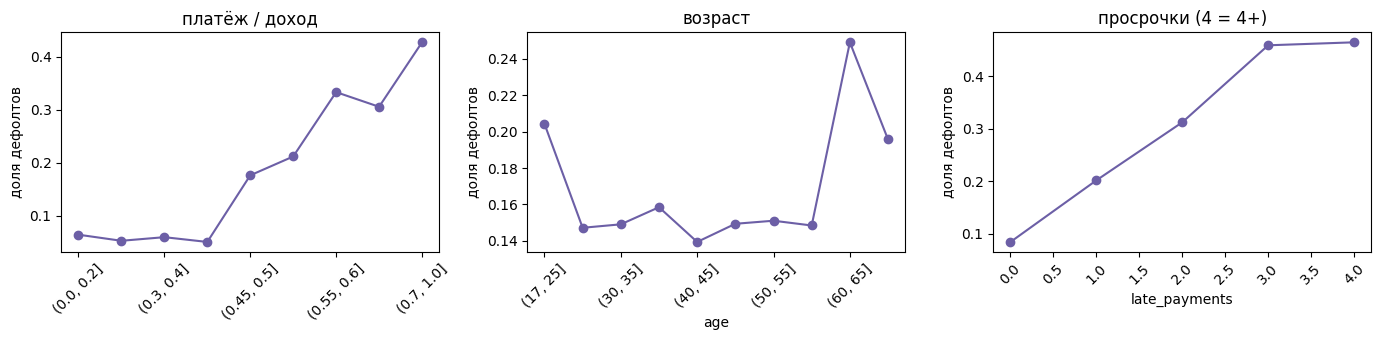

In [6]:
share = df["monthly_payment"] / df["income"]
share_bins = pd.cut(share, [0, 0.2, 0.3, 0.4, 0.45, 0.5, 0.55, 0.6, 0.7, 1, 5])
age_bins = pd.cut(df["age"], [17, 25, 30, 35, 40, 45, 50, 55, 60, 65, 75])
late = df["late_payments"].clip(upper=4)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
df.groupby(share_bins, observed=True)["default"].mean().plot(ax=ax[0], marker="o", color=PURPLE)
df.groupby(age_bins, observed=True)["default"].mean().plot(ax=ax[1], marker="o", color=PURPLE)
df.groupby(late)["default"].mean().plot(ax=ax[2], marker="o", color=PURPLE)
ax[0].set_title("платёж / доход"); ax[1].set_title("возраст"); ax[2].set_title("просрочки (4 = 4+)")
for a in ax:
    a.set_ylabel("доля дефолтов"); a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

Все три зависимости **нелинейные**:
- по доле платежа — **порог**: до 40% риск почти не растёт, после 50% резко подскакивает;
- по возрасту — **U-образная**: рискованнее самые молодые и самые старшие;
- по просрочкам — рост с **насыщением**.

Логистическая регрессия видит каждый признак как прямую линию в логитах, и такие формы ей нужно подсказывать вручную. Дерево находит пороги само. Ансамбли деревьев — главный инструмент для таких данных.

In [7]:
df.groupby("employment")["default"].agg(["mean", "count"]).sort_values("mean")

,mean,count
employment,,
employed,0.139305,8004
self_employed,0.201389,1728
retired,0.205016,917
student,0.214511,634
unemployed,0.224547,717


## Подготовка и валидация

### Отложенный тест

Сразу откладываем 25% в **тест**. До последнего раздела мы на него не смотрим: все решения принимаем по кросс-валидации на трейне.

In [8]:
y = df["default"]
X = df.drop(columns=["client_id", "default"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=0)
print(X_train.shape, X_test.shape)

(9000, 10) (3000, 10)


### Признаки для деревьев

Деревьям не нужно масштабирование, а категории можно закодировать просто номерами: дерево разрежет номера на группы. Пропуски оставляем как есть.

In [9]:
CAT = ["employment", "region"]

def to_codes(X):
    X = X.copy()
    for c in CAT:
        X[c] = pd.Categorical(X[c], categories=sorted(df[c].unique())).codes
    return X

Xt_train, Xt_test = to_codes(X_train), to_codes(X_test)
Xt_train.head(3)

,age,employment,region,income,loan_amount,term,monthly_payment,credit_history_years,late_payments,credit_cards
6479,44,0,17,127.37,1740.19,60,45.44,11.2,1,2
323,44,0,8,41.02,434.74,36,14.48,21.7,0,1
6020,18,3,22,28.01,529.97,36,20.05,0.0,0,0


### Кросс-валидация и отложенная часть

- **5-fold CV** со стратификацией — для сравнения моделей. Каждая модель обучается 5 раз, оценка — среднее по фолдам, разброс показывает надёжность.
- Внутри трейна дополнительно выделим часть **для графиков** (`X_fit` / `X_val`): кривые «качество от числа деревьев» удобнее строить на одном разбиении.

In [10]:
folds = StratifiedKFold(5, shuffle=True, random_state=0)
cv_results = {}

def cv_auc(name, model, X=Xt_train):
    scores = cross_val_score(model, X, y_train, cv=folds, scoring="roc_auc")
    cv_results[name] = scores
    print(f"{name:25s} ROC-AUC = {scores.mean():.4f} ± {scores.std():.4f}")

In [11]:
X_fit, X_val, y_fit, y_val = train_test_split(
    Xt_train, y_train, test_size=0.25, stratify=y_train, random_state=0)
print(len(X_fit), len(X_val))

6750 2250


### Бейзлайн 1: логистическая регрессия

Линейной модели нужна подготовка: пропуски заполняем медианой, числа масштабируем, категории кодируем one-hot. Всё собираем в `pipeline`, чтобы на каждом фолде подготовка обучалась только на трейне фолда.

In [13]:
num_cols = [c for c in X.columns if c not in CAT]

prep = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
    (OneHotEncoder(handle_unknown="ignore"), CAT),
)
logreg = make_pipeline(prep, LogisticRegression(max_iter=1000))

cv_auc("логрег", logreg, X_train)

логрег                    ROC-AUC = 0.8020 ± 0.0042


### Бейзлайн 2: одно дерево

У дерева главный параметр — глубина. Посмотрим, как меняется качество на обучении и на отложенной части.

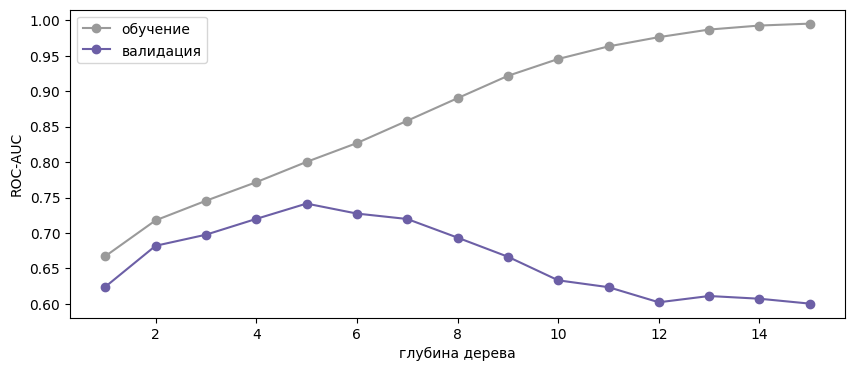

In [ ]:
depths = range(1, 16)
train_auc, val_auc = [], []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_fit, y_fit)
    train_auc.append(roc_auc_score(y_fit, tree.predict_proba(X_fit)[:, 1]))
    val_auc.append(roc_auc_score(y_val, tree.predict_proba(X_val)[:, 1]))

plt.plot(depths, train_auc, marker="o", color=GREY, label="обучение")
plt.plot(depths, val_auc, marker="o", color=PURPLE, label="валидация")
plt.xlabel("глубина дерева"); plt.ylabel("ROC-AUC"); plt.legend(); plt.show()

Классическая картина:
- **мелкое дерево** — недообучение, высокое **смещение**: слишком грубые правила;
- **глубокое дерево** — на обучении почти 1, на валидации всё хуже: высокий **разброс**, дерево запоминает шум.

Лучшее одно дерево — где-то посередине.

In [ ]:
cv_auc("одно дерево (глубина 5)", DecisionTreeClassifier(max_depth=5, random_state=0))

одно дерево (глубина 5)   ROC-AUC = 0.7547 ± 0.0203


### Насколько неустойчиво глубокое дерево

Обучим 5 глубоких деревьев на разных случайных 80% обучающих данных и посмотрим на их прогнозы для одних и тех же клиентов — возьмём шестерых, кто на самом деле ушёл в дефолт.

In [16]:
clients = X_val[y_val == 1].head(6)
preds = {}
for s in range(5):
    part = X_fit.sample(frac=0.8, random_state=s)
    tree = DecisionTreeClassifier(min_samples_leaf=5, random_state=0).fit(part, y_fit[part.index])
    preds[f"дерево {s}"] = tree.predict_proba(clients)[:, 1]

pd.DataFrame(preds, index=clients.index).round(2)

,дерево 0,дерево 1,дерево 2,дерево 3,дерево 4
7052,0.00,0.78,0.14,0.14,0.44
7027,1.00,0.75,0.20,0.60,0.71
3422,1.00,1.00,1.00,1.00,0.33
10201,0.00,0.00,0.20,0.00,0.33
4659,0.29,0.00,0.00,0.00,0.20
10402,0.57,0.83,0.14,0.00,0.67


Для одного и того же клиента деревья дают совершенно разные вероятности: у одного и того же клиента от 0 до 1. Каждое по отдельности ненадёжно, но ошибаются они **по-разному**. Если их усреднить, случайные ошибки частично взаимно погасятся. На этом стоит бэггинг.

## Бэггинг

### Теория

**Bootstrap aggregating** (Брейман, 1996):
1. Из обучающей выборки размера $n$ берём $n$ объектов **с возвращением** — бутстреп-выборку. Одни объекты попадут в неё несколько раз, другие ни разу.
2. На каждой из $B$ бутстреп-выборок обучаем глубокое дерево.
3. Ответ ансамбля — среднее вероятностей:
$$a(x) = \frac{1}{B}\sum_{b=1}^{B} b_b(x)$$

**Почему это работает.** Пусть у каждого дерева разброс прогноза $\sigma^2$, а корреляция прогнозов двух деревьев — $\rho$. Тогда
$$\mathbb{D}\left[\frac{1}{B}\sum_b b_b(x)\right] = \rho\,\sigma^2 + \frac{1-\rho}{B}\,\sigma^2$$

- второе слагаемое уходит к нулю с ростом $B$;
- первое не уходит: **чем более похожи деревья, тем меньше пользы от усреднения**;
- смещение не меняется: среднее одинаково смещённых деревьев смещено так же.

Поэтому в бэггинг берут **глубокие** деревья: смещение маленькое, а большой разброс лечится усреднением.

**Сколько объектов попадает в бутстреп.** Вероятность, что объект не выбран ни разу: $(1-1/n)^n \to 1/e \approx 0{,}368$. Проверим.

In [17]:
rng = np.random.default_rng(0)
n = len(X_fit)
idx = rng.integers(0, n, size=n)          # n случайных номеров строк с возвращением
print("уникальных объектов:", round(len(np.unique(idx)) / n, 3))
print("1 - 1/e =", round(1 - np.exp(-1), 3))

уникальных объектов: 0.636
1 - 1/e = 0.632


Оставшиеся ~37% объектов — **out-of-bag** (OOB) для этого дерева. Они пригодятся в разделе про лес.

### Задание 1

Допишите `bagging_predict(X_tr, y_tr, X_te, n_models, seed)`:
- создайте генератор `rng = np.random.default_rng(seed)` (уже написано);
- `n_models` раз: выберите индексы бутстрепа, обучите `DecisionTreeClassifier(min_samples_leaf=5, random_state=0)` на этих строках, прибавьте его вероятности класса 1 на `X_te` к `proba`;
- верните среднее.

*Подсказка:* строки по номерам — `X_tr.iloc[idx]`, `y_tr.iloc[idx]`; вероятность класса 1 — `tree.predict_proba(X_te)[:, 1]`.

In [18]:
def bagging_predict(X_tr, y_tr, X_te, n_models, seed=0):
    rng = np.random.default_rng(seed)
    n = len(X_tr)
    proba = np.zeros(len(X_te))
    for _ in range(n_models):
        idx = rng.integers(0, n, size=n)
        tree = DecisionTreeClassifier(min_samples_leaf=5, random_state=0)
        tree.fit(X_tr.iloc[idx], y_tr.iloc[idx])
        proba += tree.predict_proba(X_te)[:, 1]
    return proba / n_models

In [19]:
p1 = bagging_predict(X_fit, y_fit, X_val, n_models=30, seed=1)
p2 = bagging_predict(X_fit, y_fit, X_val, n_models=30, seed=1)
p3 = bagging_predict(X_fit, y_fit, X_val, n_models=30, seed=2)
one = DecisionTreeClassifier(min_samples_leaf=5, random_state=0).fit(X_fit, y_fit)

auc_one = roc_auc_score(y_val, one.predict_proba(X_val)[:, 1])
auc_bag = roc_auc_score(y_val, p1)

assert p1 is not None and len(p1) == len(X_val), "нужен массив вероятностей длины len(X_te)"
assert p1.min() >= 0 and p1.max() <= 1, "вероятности должны быть от 0 до 1"
assert np.allclose(p1, p2), "при одном seed результат должен совпадать"
assert not np.allclose(p1, p3), "разные seed должны давать разные бутстрепы"
assert auc_bag > auc_one + 0.03, "бэггинг должен заметно обгонять одно глубокое дерево"
print(f"одно глубокое дерево: {auc_one:.4f},  бэггинг из 30: {auc_bag:.4f}")
print("Верно!")

одно глубокое дерево: 0.6884,  бэггинг из 30: 0.8052
Верно!


### Качество от числа деревьев

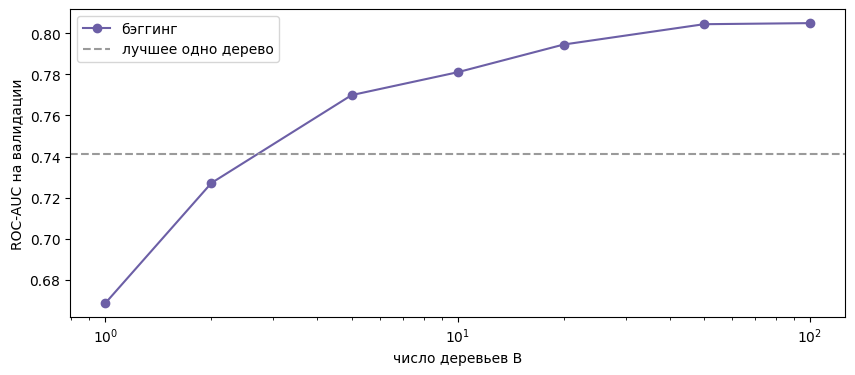

In [20]:
sizes = [1, 2, 5, 10, 20, 50, 100]
bag_auc = [roc_auc_score(y_val, bagging_predict(X_fit, y_fit, X_val, b)) for b in sizes]

plt.plot(sizes, bag_auc, marker="o", color=PURPLE, label="бэггинг")
plt.axhline(max(val_auc), color=GREY, ls="--", label="лучшее одно дерево")
plt.xscale("log"); plt.xlabel("число деревьев B"); plt.ylabel("ROC-AUC на валидации")
plt.legend(); plt.show()

- Одно глубокое дерево хуже лучшего мелкого, но уже 10 глубоких деревьев вместе обгоняют его.
- Дальше рост замедляется и выходит на плато: остаётся слагаемое $\rho\sigma^2$, которое усреднением не убрать.
- Переобучения от добавления деревьев нет: каждое новое дерево лишь уточняет среднее.

## Случайный лес

### Теория

Деревья в бэггинге всё ещё **похожи**: самые сильные признаки (просрочки, платёж) почти всегда оказываются наверху. Значит, $\rho$ велико, и плато наступает рано.

**Случайный лес** (Брейман, 2001) = бэггинг + случайные признаки: в **каждом узле** лучший порог ищется не по всем $d$ признакам, а по случайным $m$ из них (`max_features`).
- $m = d$ — обычный бэггинг;
- маленькое $m$ — деревья сильно различаются (меньше $\rho$), но каждое хуже;
- обычно $m=\sqrt d$ для классификации — компромисс.

**Extra Trees** идут дальше: порог в узле тоже выбирается случайно, а не оптимально. Деревья ещё разнообразнее, обучение быстрее.

Проверим, правда ли деревья леса меньше коррелированы. Обучим лес с `max_features=None` (то есть бэггинг) и с `"sqrt"` и посчитаем среднюю корреляцию прогнозов деревьев на валидации.

In [29]:
def tree_predictions(forest, X):
    # прогнозы каждого дерева: матрица (число деревьев × число объектов)
    return np.array([t.predict_proba(X.values)[:, 1] for t in forest.estimators_])

def mean_corr(P):
    C = np.corrcoef(P)
    return C[np.triu_indices_from(C, k=1)].mean()

forests = {
    "бэггинг (все признаки)": RandomForestClassifier(300, max_features=None, min_samples_leaf=5, n_jobs=-1, random_state=0),
    "случайный лес (sqrt)":   RandomForestClassifier(300, max_features="sqrt", min_samples_leaf=5, n_jobs=-1, random_state=0),
    "Extra Trees (sqrt)":     ExtraTreesClassifier(300, max_features="sqrt", min_samples_leaf=5, n_jobs=-1, random_state=0),
}
tree_preds = {}
for name, f in forests.items():
    f.fit(X_fit, y_fit)
    tree_preds[name] = tree_predictions(f, X_val)
    print(f"{name:25s} корреляция деревьев = {mean_corr(tree_preds[name]):.3f}")

бэггинг (все признаки)    корреляция деревьев = 0.406
случайный лес (sqrt)      корреляция деревьев = 0.347
Extra Trees (sqrt)        корреляция деревьев = 0.454


У леса корреляция деревьев ниже, чем у бэггинга. У Extra Trees она даже выше — но это не противоречие: случайные пороги делают каждое дерево грубее и **устойчивее**, то есть уменьшают сам разброс $\sigma^2$ одного дерева. В формуле важны оба множителя.

Теперь качество в зависимости от числа деревьев. Для этого не нужно переобучать лес: усредним прогнозы первых $k$ деревьев.

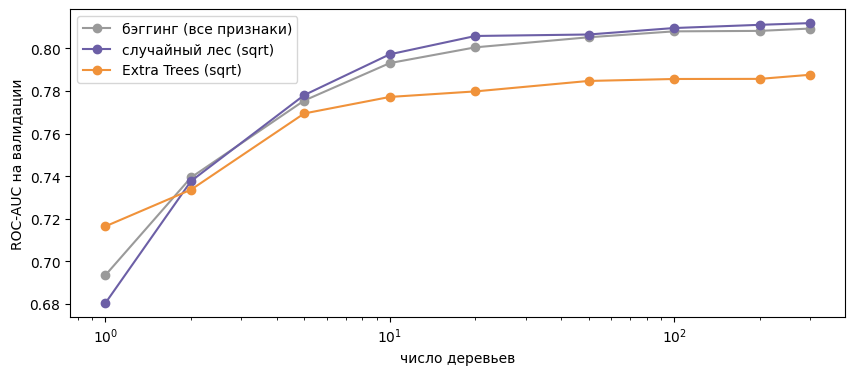

In [22]:
ks = [1, 2, 5, 10, 20, 50, 100, 200, 300]
for (name, P), color in zip(tree_preds.items(), [GREY, PURPLE, ORANGE]):
    curve = [roc_auc_score(y_val, P[:k].mean(axis=0)) for k in ks]
    plt.plot(ks, curve, marker="o", color=color, label=name)

plt.xscale("log"); plt.xlabel("число деревьев"); plt.ylabel("ROC-AUC на валидации")
plt.legend(); plt.show()

Одно дерево случайного леса **хуже** дерева бэггинга: ему достаются случайные признаки. Но ансамбль из таких деревьев лучше — меньше корреляция, ниже плато. Ровно то, что предсказывает формула $\rho\sigma^2 + \frac{1-\rho}{B}\sigma^2$.

### OOB-оценка

Каждое дерево не видело ~37% объектов. Для объекта усредним прогнозы только тех деревьев, которые его не видели, — получим **честный прогноз без отдельной валидации**. В sklearn: `oob_score=True`, прогнозы лежат в `oob_decision_function_`.

In [30]:
rf = RandomForestClassifier(300, max_features="sqrt", min_samples_leaf=5,
                            oob_score=True, n_jobs=-1, random_state=0).fit(X_fit, y_fit)

oob_auc = roc_auc_score(y_fit, rf.oob_decision_function_[:, 1])
val_rf = roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1])
print(f"OOB ROC-AUC: {oob_auc:.4f}   на валидации: {val_rf:.4f}")

OOB ROC-AUC: 0.8197   на валидации: 0.8119


OOB-оценка близка к валидационной — это бесплатная замена кросс-валидации для леса. Используем её, чтобы подобрать `max_features`: для каждого значения обучаем один лес вместо пяти.

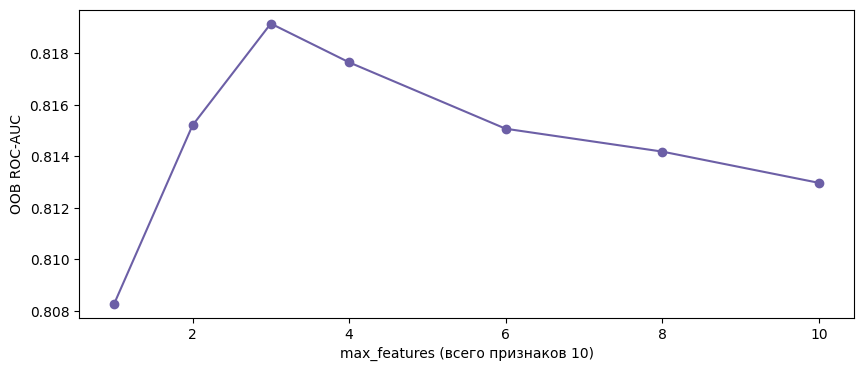

In [31]:
m_values = [1, 2, 3, 4, 6, 8, 10]
oob = []
for m in m_values:
    f = RandomForestClassifier(200, max_features=m, min_samples_leaf=5,
                               oob_score=True, n_jobs=-1, random_state=0).fit(X_fit, y_fit)
    oob.append(roc_auc_score(y_fit, f.oob_decision_function_[:, 1]))

plt.plot(m_values, oob, marker="o", color=PURPLE)
plt.xlabel("max_features (всего признаков 10)"); plt.ylabel("OOB ROC-AUC"); plt.show()

Оптимум — небольшое $m$ (2–4, между ними разница в пределах шума), а $m = 10$ (обычный бэггинг) заметно хуже. Сравним модели по кросс-валидации.

In [25]:
cv_auc("случайный лес", RandomForestClassifier(500, max_features=3, min_samples_leaf=5, n_jobs=-1, random_state=0))
cv_auc("Extra Trees", ExtraTreesClassifier(500, max_features=3, min_samples_leaf=5, n_jobs=-1, random_state=0))

случайный лес             ROC-AUC = 0.8193 ± 0.0071
Extra Trees               ROC-AUC = 0.8080 ± 0.0047


## 5. Важность признаков

### Теория

**MDI** (`feature_importances_`, mean decrease in impurity) — сумма приростов критерия по всем узлам, где разбивали по признаку. Считается бесплатно, но по **обучающим** данным. Поэтому она завышает признаки с большим числом уникальных значений: на них проще найти «удачный» порог, даже если признак — шум.

**Permutation importance** — насколько упадёт качество на **валидации**, если перемешать один столбец:
1. считаем ROC-AUC модели на валидации;
2. случайно переставляем значения столбца `col` — связь признака с целью разрушена, распределение сохранено;
3. считаем ROC-AUC снова; важность = падение качества.

Если модель на признак не опирается, перемешивание ничего не изменит и важность будет около нуля.

Проверим на типичной ошибке: забыли удалить `client_id`. Это просто номер заявки, информации в нём нет.

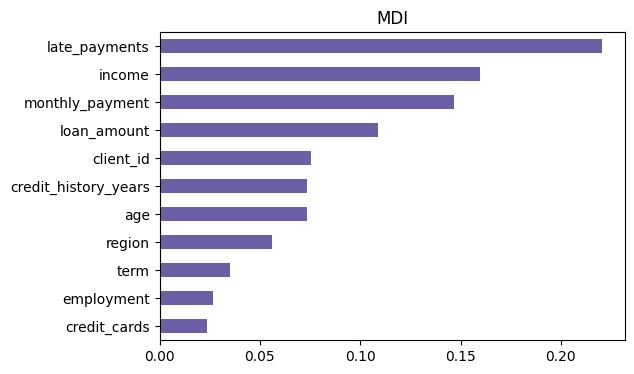

In [32]:
X_fit_id = X_fit.assign(client_id=df.loc[X_fit.index, "client_id"])
X_val_id = X_val.assign(client_id=df.loc[X_val.index, "client_id"])

rf_id = RandomForestClassifier(300, max_features=3, min_samples_leaf=5,
                               n_jobs=-1, random_state=0).fit(X_fit_id, y_fit)
mdi = pd.Series(rf_id.feature_importances_, index=X_fit_id.columns).sort_values()
mdi.plot.barh(figsize=(6, 4), color=PURPLE); plt.title("MDI"); plt.show()

По MDI `client_id` выглядит заметным признаком — лес нарезал его на мелкие куски и подогнал под шум обучения.

### Задание 2

Допишите `permutation_drop(model, X, y, col, seed)` — падение ROC-AUC при перемешивании столбца `col`.

- исходный AUC уже посчитан;
- сделайте копию `X` (исходную таблицу **не меняем**!), перемешайте в ней столбец `col`;
- посчитайте AUC на копии и верните разность `base - shuffled`.

*Подсказка:* `rng.permutation(X[col].values)` возвращает перемешанный массив.

In [34]:
def permutation_drop(model, X, y, col, seed=0):
    rng = np.random.default_rng(seed)
    base = roc_auc_score(y, model.predict_proba(X)[:, 1])
    X_shuf = X.copy()
    X_shuf[col] = rng.permutation(X_shuf[col].values)
    shuffled = roc_auc_score(y, model.predict_proba(X_shuf)[:, 1])
    return base - shuffled

In [35]:
before = X_val_id.copy()
d_late = permutation_drop(rf_id, X_val_id, y_val, "late_payments", seed=0)
d_id = permutation_drop(rf_id, X_val_id, y_val, "client_id", seed=0)

assert d_late is not None, "функция должна вернуть число"
assert X_val_id.equals(before), "исходную таблицу менять нельзя — работайте с копией"
assert d_late == permutation_drop(rf_id, X_val_id, y_val, "late_payments", seed=0), "при одном seed результат одинаковый"
assert d_late > 0.02, "перемешивание просрочек должно заметно ухудшать модель"
assert abs(d_id) < 0.01, "client_id не несёт информации — падение должно быть около нуля"
print(f"late_payments: {d_late:.4f},  client_id: {d_id:.4f}")
print("Верно!")

late_payments: 0.1316,  client_id: -0.0002
Верно!


Посчитаем для всех признаков. Перемешивание случайно, поэтому повторим 5 раз и усредним.

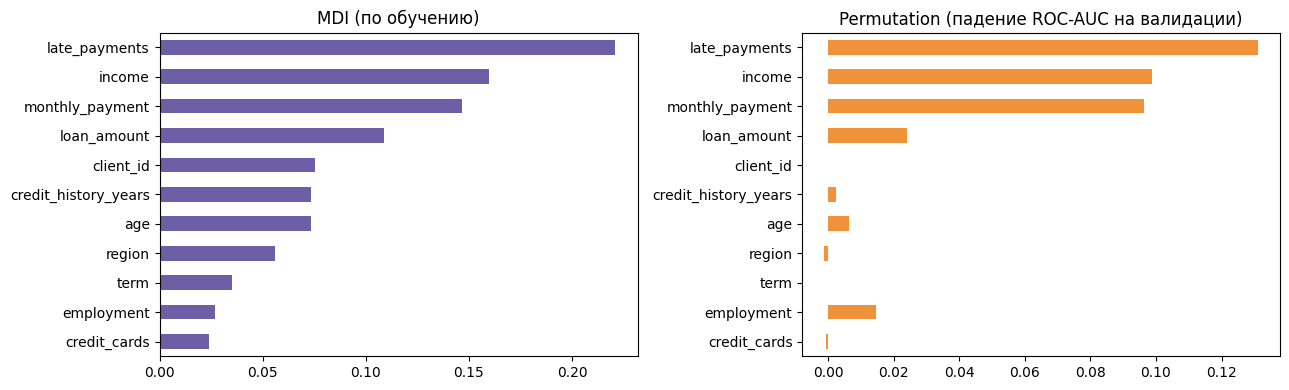

In [36]:
perm = {}
for col in X_val_id.columns:
    perm[col] = np.mean([permutation_drop(rf_id, X_val_id, y_val, col, seed=s) for s in range(5)])
perm = pd.Series(perm)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
mdi.plot.barh(ax=ax[0], color=PURPLE); ax[0].set_title("MDI (по обучению)")
perm[mdi.index].plot.barh(ax=ax[1], color=ORANGE); ax[1].set_title("Permutation (падение ROC-AUC на валидации)")
plt.tight_layout(); plt.show()

- По permutation `client_id` — около нуля: модель его использует, но на новых данных это ничего не даёт.
- Сильнее всего падает качество без просрочек и платежа.
- Permutation честнее, но дороже: нужно много прогнозов. Есть и готовая функция — `sklearn.inspection.permutation_importance`.
- Осторожно с коррелированными признаками: `monthly_payment`, `loan_amount` и `term` связаны, при перемешивании одного модель частично «достаёт» информацию из других, и каждый кажется слабее, чем есть.

## Градиентный бустинг своими руками

### Теория

Лес усредняет **независимые** сильные деревья и снижает разброс. Бустинг устроен наоборот: строит **неглубокие** деревья **по очереди**, каждое исправляет ошибки уже построенного ансамбля, и так снижает смещение.

Модель — сумма:
$$F_M(x) = F_0 + \nu \sum_{m=1}^{M} b_m(x)$$

Для классификации $F(x)$ — **логит**, вероятность $p = \sigma(F) = \frac{1}{1+e^{-F}}$, потери — log-loss.

**Шаг 0.** $F_0$ — лучшая константа: логит доли класса 1, $F_0 = \ln\frac{\bar y}{1-\bar y}$.

**Шаг $m$.**
1. Считаем **псевдоостатки** — антиградиент потерь по текущему прогнозу. Для log-loss он удивительно простой:
$$r_i = -\frac{\partial L}{\partial F(x_i)} = y_i - p_i$$
   Клиент с дефолтом ($y=1$), которому модель дала $p = 0{,}1$, получает остаток $+0{,}9$: «подними его логит». Хороший клиент с $p=0{,}1$ получает $-0{,}1$: «чуть опусти».
2. Обучаем **регрессионное** дерево предсказывать $r_i$ по $x_i$. Оно обобщает «куда двигать» с обучающих точек на всё пространство.
3. Делаем маленький шаг: $F \leftarrow F + \nu \cdot b_m(x)$. Learning rate $\nu$ не даёт сразу доверять одному дереву.

Это градиентный спуск, только шагаем не по параметрам, а по значениям функции, и каждый шаг — дерево.

> В библиотеках значения в листьях дополнительно уточняют шагом Ньютона (сумма градиентов / сумма вторых производных). Мы делаем чистый градиентный шаг: работает так же по смыслу, просто чуть медленнее сходится.

### Задание 3

Допишите `fit_boosting(X, y, n_trees, lr, max_depth)`. Функция возвращает словарь `{"F0": ..., "lr": ..., "trees": [...]}`.
- посчитайте `F0` — логит доли единиц;
- `F` — текущие логиты на обучении, в начале все равны `F0`;
- в цикле: остатки `y - sigmoid(F)` → `DecisionTreeRegressor(max_depth=max_depth, random_state=0)` на остатках → `F = F + lr * tree.predict(X)` → дерево в список.

`predict_boosting` уже написана: она повторяет те же сложения для новых данных.

In [37]:
def sigmoid(F):
    return 1 / (1 + np.exp(-F))

def predict_boosting(model, X):
    F = np.full(len(X), model["F0"])
    for tree in model["trees"]:
        F = F + model["lr"] * tree.predict(X)
    return sigmoid(F)

In [38]:
def fit_boosting(X, y, n_trees=100, lr=0.1, max_depth=3):
    y = np.asarray(y, float)
    trees = []
    F0 = np.log(y.mean() / (1 - y.mean()))
    F = np.full(len(y), F0)
    for _ in range(n_trees):
        residual = y - sigmoid(F)
        tree = DecisionTreeRegressor(max_depth=max_depth, random_state=0).fit(X, residual)
        F = F + lr * tree.predict(X)
        trees.append(tree)
    return {"F0": F0, "lr": lr, "trees": trees}

In [39]:
def _ref_boosting(X, y, n_trees, lr, max_depth):
    y = np.asarray(y, float)
    F0 = np.log(y.mean() / (1 - y.mean())); F = np.full(len(y), F0); trees = []
    for _ in range(n_trees):
        t = DecisionTreeRegressor(max_depth=max_depth, random_state=0).fit(X, y - sigmoid(F))
        F = F + lr * t.predict(X); trees.append(t)
    return {"F0": F0, "lr": lr, "trees": trees}

small_X, small_y = X_fit.head(2000), y_fit.head(2000)
mine = fit_boosting(small_X, small_y, n_trees=20, lr=0.2, max_depth=2)
ref = _ref_boosting(small_X, small_y, 20, 0.2, 2)

assert mine["F0"] is not None and np.isclose(mine["F0"], ref["F0"]), "F0 — логит доли класса 1"
assert len(mine["trees"]) == 20, "должно получиться n_trees деревьев"
assert np.allclose(predict_boosting(mine, X_val), predict_boosting(ref, X_val)), "прогнозы не совпадают с эталоном"
losses = [log_loss(small_y, predict_boosting({**mine, "trees": mine["trees"][:k]}, small_X)) for k in range(21)]
assert all(np.diff(losses) < 0), "log-loss на обучении должен падать с каждым деревом"
print("log-loss на обучении:", round(losses[0], 4), "→", round(losses[-1], 4))
print("Верно!")

log-loss на обучении: 0.4372 → 0.3973
Верно!


### Что выучило первое дерево

Псевдоостатки на первом шаге: $+0{,}84$ у дефолтов и $-0{,}16$ у остальных. Первое дерево ищет области, где дефолтов больше среднего.

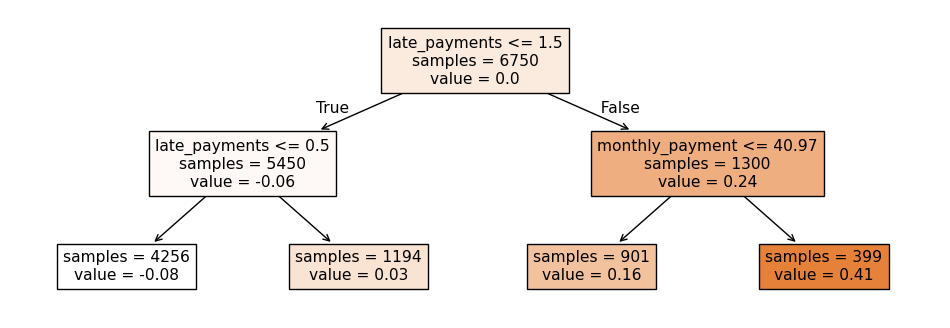

In [40]:
boost = fit_boosting(X_fit, y_fit, n_trees=1, lr=0.1, max_depth=2)
plt.figure(figsize=(12, 4))
plot_tree(boost["trees"][0], feature_names=list(X_fit.columns), filled=True, impurity=False, precision=2)
plt.show()

`value` в листе — средний остаток, то есть насколько в этой области нужно сдвинуть логит. Дерево сразу нашло главное: просрочки и высокий платёж.

### Learning rate и число деревьев

Чтобы построить кривую, не нужно обучать заново: прогноз после $k$ деревьев — это сумма первых $k$ слагаемых. Функция `staged_logloss` считает log-loss после каждого дерева.

In [41]:
def staged_logloss(model, X, y):
    F = np.full(len(X), model["F0"])
    out = []
    for tree in model["trees"]:
        F = F + model["lr"] * tree.predict(X)
        out.append(log_loss(y, sigmoid(F)))
    return out

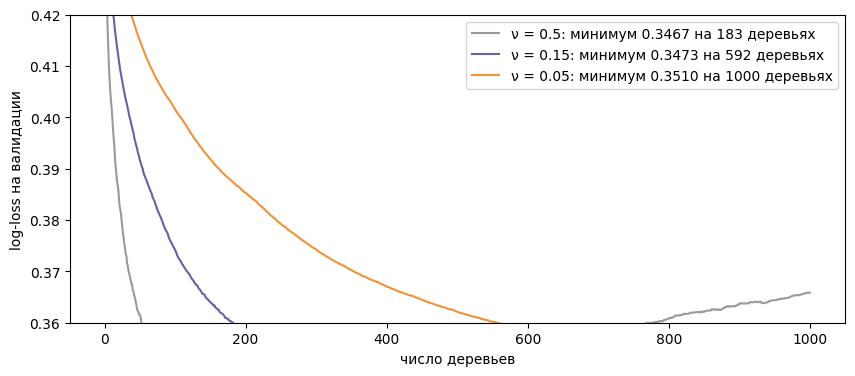

In [42]:
my_boost = {}
for lr, color in [(0.5, GREY), (0.15, PURPLE), (0.05, ORANGE)]:
    my_boost[lr] = fit_boosting(X_fit, y_fit, n_trees=1000, lr=lr, max_depth=3)
    curve = staged_logloss(my_boost[lr], X_val, y_val)
    best = int(np.argmin(curve))
    plt.plot(range(1, 1001), curve, color=color, label=f"ν = {lr}: минимум {curve[best]:.4f} на {best + 1} деревьях")
    plt.scatter(best + 1, curve[best], color=color, zorder=3)

plt.ylim(0.36, 0.42); plt.xlabel("число деревьев"); plt.ylabel("log-loss на валидации")
plt.legend(); plt.show()

Главная разница с лесом:
- **бустинг переобучается от числа деревьев**: после минимума ошибка на валидации растёт, потому что новые деревья начинают подгоняться под шум;
- **большой $\nu$** — быстро доходит до минимума и быстро переобучается; минимум хуже;
- **маленький $\nu$** — деревьев нужно в разы больше ($\nu \cdot M \approx$ const), зато кривая пологая: ошибиться с числом деревьев не страшно, а минимум обычно не хуже.

Отсюда стандартный рецепт: маленький learning rate + **ранняя остановка** по валидации.

Сравним нашу реализацию с LightGBM при тех же настройках: $\nu = 0{,}15$, глубина 3, 300 деревьев.

In [44]:
k = 300
mine_auc = roc_auc_score(y_val, predict_boosting({**my_boost[0.15], "trees": my_boost[0.15]["trees"][:k]}, X_val))

lib = lgb.LGBMClassifier(n_estimators=k, learning_rate=0.15, max_depth=3, num_leaves=8, verbose=-1).fit(X_fit, y_fit)
lib_auc = roc_auc_score(y_val, lib.predict_proba(X_val)[:, 1])
print(f"наш бустинг: {mine_auc:.4f}   LightGBM: {lib_auc:.4f}")

наш бустинг: 0.8116   LightGBM: 0.8055


Результаты близки: в LightGBM та же идея, плюс шаг Ньютона в листьях, регуляризация, гистограммы признаков и оптимизированный код — он быстрее в десятки раз.

## LightGBM: ранняя остановка и настройка

### Ранняя остановка

Ставим заведомо много деревьев и маленький $\nu$. Следим за качеством на валидации и останавливаемся, если 100 деревьев подряд нет улучшения.

лучшее число деревьев: 216


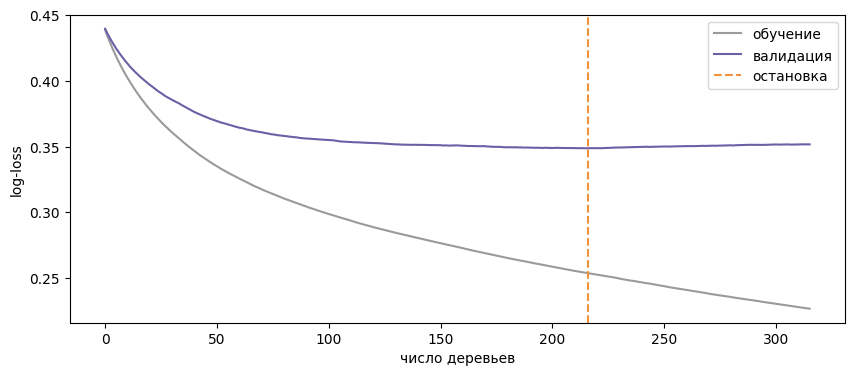

In [45]:
es_model = lgb.LGBMClassifier(n_estimators=5000, learning_rate=0.02, verbose=-1)
es_model.fit(X_fit, y_fit,
             eval_set=[(X_fit, y_fit), (X_val, y_val)], eval_names=["обучение", "валидация"],
             callbacks=[lgb.early_stopping(100, verbose=False)])

print("лучшее число деревьев:", es_model.best_iteration_)
for name, res in es_model.evals_result_.items():
    plt.plot(res["binary_logloss"], label=name, color=GREY if name == "обучение" else PURPLE)
plt.axvline(es_model.best_iteration_, color=ORANGE, ls="--", label="остановка")
plt.xlabel("число деревьев"); plt.ylabel("log-loss"); plt.legend(); plt.show()

На обучении ошибка падает всегда, на валидации — до минимума. Важно: валидация для ранней остановки — это **не тест**. Если подбирать число деревьев по тесту, оценка на нём станет оптимистичной.

### Настройка сложности деревьев

Главные параметры:
- `num_leaves` — сколько листьев в дереве (сложность одного дерева, глубина взаимодействий);
- `min_child_samples` — минимум объектов в листе (защита от листьев «под шум»);
- `subsample` / `colsample_bytree` — доля объектов и признаков для каждого дерева (стохастический бустинг, как в лесу);
- `reg_lambda` — L2-штраф на значения листьев.

Для каждого набора параметров запускаем `lgb.cv`: 5-fold CV с ранней остановкой, число деревьев подбирается внутри. Оценка слегка оптимистична (остановку выбирали по тем же фолдам), но для сравнения настроек её достаточно.

In [46]:
def lgb_cv(params):
    full = {"objective": "binary", "metric": "auc", "learning_rate": 0.03, "verbose": -1, **params}
    res = lgb.cv(full, lgb.Dataset(Xt_train, y_train), num_boost_round=5000, folds=folds,
                 callbacks=[lgb.early_stopping(100, verbose=False)])
    return res["valid auc-mean"][-1], len(res["valid auc-mean"])

In [47]:
rows = []
for leaves in [4, 8, 16, 32]:
    for min_child in [20, 100, 300]:
        auc, n_trees = lgb_cv({"num_leaves": leaves, "min_child_samples": min_child})
        rows.append({"num_leaves": leaves, "min_child_samples": min_child, "auc": auc, "деревьев": n_trees})

grid = pd.DataFrame(rows).sort_values("auc", ascending=False)
grid.head(6).round(4)

,num_leaves,min_child_samples,auc,деревьев
5,8,300,0.8310,353
11,32,300,0.8307,193
8,16,300,0.8306,208
2,4,300,0.8305,707
4,8,100,0.8304,261
1,4,100,0.8302,600


In [48]:
grid.pivot(index="num_leaves", columns="min_child_samples", values="auc").round(4)

min_child_samples,20,100,300
num_leaves,,,
4,0.8294,0.8302,0.8305
8,0.8299,0.8304,0.8310
16,0.8276,0.8293,0.8306
32,0.8240,0.8256,0.8307


Добавим к лучшему варианту стохастичность и L2-регуляризацию.

In [49]:
best = grid.iloc[0]
params = {"num_leaves": int(best["num_leaves"]), "min_child_samples": int(best["min_child_samples"])}

for extra in [{}, {"subsample": 0.8, "subsample_freq": 1, "colsample_bytree": 0.8},
              {"subsample": 0.8, "subsample_freq": 1, "colsample_bytree": 0.8, "reg_lambda": 10}]:
    auc, n_trees = lgb_cv({**params, **extra})
    print(f"{auc:.4f}  деревьев: {n_trees:4d}  {extra}")

0.8310  деревьев:  353  {}
0.8318  деревьев:  329  {'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.8}
0.8319  деревьев:  329  {'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.8, 'reg_lambda': 10}


Берём лучший набор и фиксируем число деревьев, найденное ранней остановкой. Дальше модель с этими параметрами участвует в общем сравнении.

In [50]:
final_params = {**params, "subsample": 0.8, "subsample_freq": 1, "colsample_bytree": 0.8, "reg_lambda": 10}
_, best_rounds = lgb_cv(final_params)

def make_lgb():
    return lgb.LGBMClassifier(n_estimators=best_rounds, learning_rate=0.03, verbose=-1, **final_params)

cv_auc("LightGBM", make_lgb())

LightGBM                  ROC-AUC = 0.8315 ± 0.0073


### Промежуточный итог

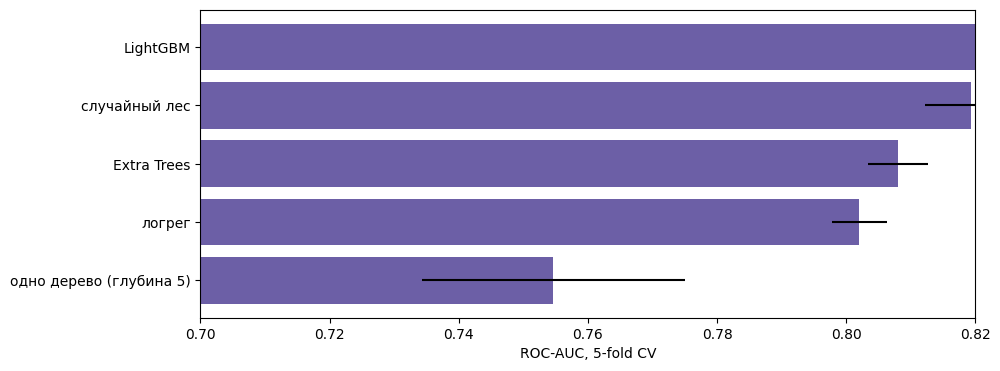

In [51]:
summary = pd.DataFrame({k: [v.mean(), v.std()] for k, v in cv_results.items()}, index=["auc", "std"]).T
summary = summary.sort_values("auc")
plt.barh(summary.index, summary["auc"], xerr=summary["std"], color=PURPLE)
plt.xlim(0.7, 0.82); plt.xlabel("ROC-AUC, 5-fold CV"); plt.show()

## Стекинг

### Теория

Разные модели ошибаются по-разному: логрег гладкий и хорошо экстраполирует, лес устойчив, бустинг точнее ловит взаимодействия. **Стекинг** учит метамодель комбинировать их прогнозы:
- **уровень 1**: несколько разных моделей;
- **уровень 2**: метамодель (обычно логистическая регрессия), её признаки — прогнозы моделей уровня 1.

**Ловушка.** Если обучить модели уровня 1 на всём трейне и взять их прогнозы на том же трейне, метамодель увидит прогнозы переобученных моделей: лес на обучении почти не ошибается. Метамодель решит «верь лесу всегда» — а на тесте лес ошибается куда чаще.

**Решение — out-of-fold (OOF) прогнозы.** Делим трейн на $K$ фолдов. Для каждого фолда обучаем модель на остальных $K-1$ и предсказываем этот фолд. В итоге у каждого объекта есть прогноз модели, которая его **не видела** — как на тесте.

```
фолд:     1     2     3     4     5
модель 1: прог  обуч  обуч  обуч  обуч   → OOF для фолда 1
модель 2: обуч  прог  обуч  обуч  обуч   → OOF для фолда 2
...
```

### Задание 4

Допишите `oof_predict(make_model, X, y, folds)`:
- `make_model` — функция без аргументов, возвращает **новую** необученную модель;
- для каждой пары `(tr_idx, va_idx)` из `folds.split(X, y)`: создайте модель, обучите на `X.iloc[tr_idx]`, `y.iloc[tr_idx]`, запишите вероятности класса 1 для `X.iloc[va_idx]` в `oof[va_idx]`;
- верните `oof`.

In [52]:
def oof_predict(make_model, X, y, folds):
    oof = np.zeros(len(X))
    for tr_idx, va_idx in folds.split(X, y):
        model = make_model()
        model.fit(X.iloc[tr_idx], y.iloc[tr_idx])
        oof[va_idx] = model.predict_proba(X.iloc[va_idx])[:, 1]
    return oof

In [53]:
make_logreg = lambda: make_pipeline(prep, LogisticRegression(max_iter=1000))
mine = oof_predict(make_logreg, X_train, y_train, folds)
ref = cross_val_predict(make_logreg(), X_train, y_train, cv=folds, method="predict_proba")[:, 1]
assert mine.shape == (len(X_train),) and (mine > 0).all(), "прогноз должен быть у каждого объекта"
assert np.allclose(mine, ref), "не совпадает с cross_val_predict"

make_1nn = lambda: make_pipeline(SimpleImputer(), KNeighborsClassifier(n_neighbors=1))
leak = roc_auc_score(y_train, make_1nn().fit(Xt_train, y_train).predict_proba(Xt_train)[:, 1])
honest = roc_auc_score(y_train, oof_predict(make_1nn, Xt_train, y_train, folds))
assert honest < 0.7, "OOF-прогноз не должен видеть сам объект"
print(f"1-NN, прогноз на обучении: {leak:.3f}  (утечка),  OOF: {honest:.3f}")
print("Верно!")

1-NN, прогноз на обучении: 1.000  (утечка),  OOF: 0.545
Верно!


Пример с 1-NN показывает ловушку в чистом виде: на обучении ближайший сосед объекта — он сам, и AUC = 1. OOF-прогноз честный.

### Собираем OOF-прогнозы моделей уровня 1

Логрег обучаем на исходных признаках (с подготовкой в pipeline), деревья — на закодированных. Порядок строк одинаковый, поэтому прогнозы можно класть в одну таблицу.

In [54]:
level1 = {
    "логрег":        (make_logreg, X_train),
    "случайный лес": (lambda: RandomForestClassifier(500, max_features=3, min_samples_leaf=5, n_jobs=-1, random_state=0), Xt_train),
    "Extra Trees":   (lambda: ExtraTreesClassifier(500, max_features=3, min_samples_leaf=5, n_jobs=-1, random_state=0), Xt_train),
    "LightGBM":      (make_lgb, Xt_train),
}
OOF = pd.DataFrame({name: oof_predict(make, Xm, y_train, folds) for name, (make, Xm) in level1.items()})
OOF.apply(lambda p: roc_auc_score(y_train, p)).round(4)

логрег           0.8017
случайный лес    0.8183
Extra Trees      0.8071
LightGBM         0.8308
dtype: float64

### Насколько модели похожи

Для ROC-AUC важен порядок объектов, поэтому смотрим ранговую корреляцию (Спирмена) OOF-прогнозов.

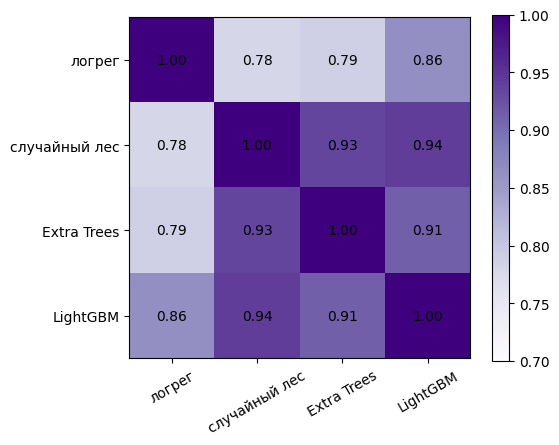

In [55]:
corr = OOF.corr(method="spearman")
plt.figure(figsize=(5.5, 4.5))
plt.imshow(corr, cmap="Purples", vmin=0.7, vmax=1)
plt.xticks(range(4), corr.columns, rotation=30); plt.yticks(range(4), corr.columns)
for i in range(4):
    for j in range(4):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.colorbar(); plt.show()

Чем меньше корреляция, тем больше потенциальная польза от объединения. Лес и Extra Trees почти одинаковы — вместе они мало добавят. Логрег отличается от деревьев сильнее всех.

### Метамодель

Признаки метамодели — логиты OOF-прогнозов: в логитах логистическая регрессия комбинирует модели естественнее, чем в вероятностях. Качество стекинга тоже оцениваем по кросс-валидации — теперь уже на таблице OOF.

In [56]:
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

S = logit(OOF)
meta = LogisticRegression()
cv_results["стекинг"] = cross_val_score(meta, S, y_train, cv=folds, scoring="roc_auc")
print(f"стекинг: {cv_results['стекинг'].mean():.4f} ± {cv_results['стекинг'].std():.4f}")

meta.fit(S, y_train)
pd.Series(meta.coef_[0], index=S.columns).round(3)

стекинг: 0.8321 ± 0.0074


логрег           0.165
случайный лес    0.063
Extra Trees     -0.085
LightGBM         0.924
dtype: float64

Коэффициенты показывают, кому метамодель доверяет. Для сравнения — простой **блендинг**: среднее рангов прогнозов без обучения.

In [57]:
for cols in [["LightGBM", "логрег"], ["LightGBM", "случайный лес", "логрег"], list(OOF.columns)]:
    blend = OOF[cols].rank().mean(axis=1)
    print(f"{roc_auc_score(y_train, blend):.4f}  среднее рангов: {', '.join(cols)}")

0.8261  среднее рангов: LightGBM, логрег
0.8293  среднее рангов: LightGBM, случайный лес, логрег
0.8277  среднее рангов: логрег, случайный лес, Extra Trees, LightGBM


## Финальная проверка на тесте

Теперь впервые смотрим на тест. Каждую модель обучаем на **всём трейне** и предсказываем тест. Для стекинга модели уровня 1 обучены на всём трейне, метамодель — на OOF-прогнозах.

In [58]:
test_pred = {}
for name, (make, Xm) in level1.items():
    X_te = X_test if name == "логрег" else Xt_test
    test_pred[name] = make().fit(Xm, y_train).predict_proba(X_te)[:, 1]

tree5 = DecisionTreeClassifier(max_depth=5, random_state=0).fit(Xt_train, y_train)
test_pred["одно дерево"] = tree5.predict_proba(Xt_test)[:, 1]
test_pred["бэггинг (наш, 100)"] = bagging_predict(Xt_train, y_train, Xt_test, n_models=100)

Наш бустинг: берём $\nu = 0{,}15$ и число деревьев, которое было лучшим на валидации, и обучаем на всём трейне.

In [59]:
curve = staged_logloss(my_boost[0.15], X_val, y_val)
n_best = int(np.argmin(curve)) + 1
my_final = fit_boosting(Xt_train, y_train, n_trees=n_best, lr=0.15, max_depth=3)
test_pred[f"бустинг (наш, {n_best})"] = predict_boosting(my_final, Xt_test)

S_test = logit(pd.DataFrame({k: test_pred[k] for k in level1}))
test_pred["стекинг"] = meta.predict_proba(S_test)[:, 1]

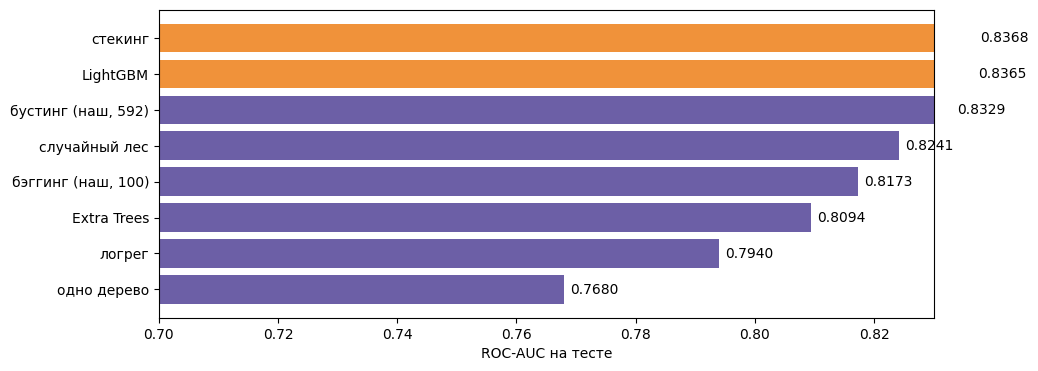

In [60]:
test_auc = pd.Series({k: roc_auc_score(y_test, p) for k, p in test_pred.items()}).sort_values()
colors = [ORANGE if k in ("стекинг", "LightGBM") else PURPLE for k in test_auc.index]
plt.barh(test_auc.index, test_auc.values, color=colors)
for i, v in enumerate(test_auc.values):
    plt.text(v + 0.001, i, f"{v:.4f}", va="center")
plt.xlim(0.7, 0.83); plt.xlabel("ROC-AUC на тесте"); plt.show()